In [1]:
import pandas as pd

train_data=pd.read_csv('../Artifacts/MinMax_Normalized_Data/train_df_normalized.csv')
test_data=pd.read_csv('../Artifacts/MinMax_Normalized_Data/test_df_normalized.csv')

# Training Part

### First we do hyperparameter tuning using optuna library.

In [2]:
# !pip uninstall torch torchvision -y
# !pip install torch torchvision --upgrade --force-reinstall

In [3]:
import torch
from torch import nn
from torch.optim import Adam
from torch.optim.lr_scheduler import OneCycleLR
from torch.nn import L1Loss, MSELoss, SmoothL1Loss
from torch.utils.data import TensorDataset, DataLoader

In [4]:
## Train test split

x_train=train_data.drop(['target','timestamp','series_id'], axis=1)
y_train=train_data['target']

x_test=test_data.drop(['target','timestamp','series_id'], axis=1)
y_test=test_data['target']

In [5]:
## Transfer those split set onto the tensors

X_train=torch.tensor(x_train.values, dtype=torch.float32)
Y_train=torch.tensor(y_train.values, dtype=torch.float32)

X_test=torch.tensor(x_test.values, dtype=torch.float32)
Y_test=torch.tensor(y_test.values, dtype=torch.float32)

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [7]:
import torch
import torch.nn as nn

class MyNN(nn.Module):
    def __init__(self, input_dim,output_dim,num_hidden_layer,neurons_per_layer,dropout_rate):
        super().__init__()

        layers=[]
        for i in range(num_hidden_layer):
            layers.append(nn.Linear(input_dim,neurons_per_layer))
            layers.append(nn.BatchNorm1d(neurons_per_layer))
            layers.append(nn.LeakyReLU())
            layers.append(nn.Dropout(dropout_rate))
            input_dim=neurons_per_layer

        layers.append(nn.Linear(neurons_per_layer,output_dim))
        self.layers=nn.Sequential(*layers)    # since sequential do not expect list we unpack list  using (*)

    def forward(self,x):
        return self.layers(x)

In [8]:
from torch.nn import MSELoss
from torch.optim import AdamW, Adam, RMSprop, SGD
from torch.optim.lr_scheduler import OneCycleLR

def objective(trial):

  # Next hyperparameter values from the search space
  num_hidden_layer = trial.suggest_int('num_hidden_layer', 1, 4)
  neurons_per_layer = trial.suggest_int('neurons_per_layer', 16, 128, step=16)
  dropout_rate = trial.suggest_float('dropout_rate', 0.0, 0.4)


  EPOCHS = 100
  BATCH_SIZE=trial.suggest_categorical('BATCH_SIZE', [32, 64, 128, 256])
  max_lr = trial.suggest_float('max_lr', 5e-4, 8e-3, log=True)
  WEIGHT_DECAY= trial.suggest_float('WEIGHT_DECAY', 1e-6, 1e-2, log=True)
  optimizer_name = trial.suggest_categorical('optimizer', ['Adam', 'AdamW'])


  # LEARNING_RATE = trial.suggest_float('LEARNING_RATE', 1e-5, 1e-3, log=True)


  train_dataset = TensorDataset(X_train, Y_train)
  train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)  ## It's simply an iterator
  test_dataset = TensorDataset(X_test, Y_test)
  test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

  # pct_start = trial.suggest_float('pct_start', 0.1, 0.4)
  # div_factor = trial.suggest_float('div_factor', 5.0, 25.0)


  # Model init
  model = MyNN(input_dim=22,output_dim=1,num_hidden_layer=num_hidden_layer,neurons_per_layer=neurons_per_layer,dropout_rate=dropout_rate)
  model.to(device)


  # Loss functin selection
  loss_fn = SmoothL1Loss(beta=1.0)


  # Optimizer selection

  if optimizer_name == 'Adam':
    optimizer = Adam(model.parameters(), lr=max_lr, weight_decay=WEIGHT_DECAY)
  elif optimizer_name == 'AdamW':
    optimizer = AdamW(model.parameters(), lr=max_lr, weight_decay=WEIGHT_DECAY)
  elif optimizer_name== 'RMSprop':
    optimizer = RMSprop(model.parameters(), lr=max_lr, weight_decay=WEIGHT_DECAY)
  else:
    optimizer = SGD(model.parameters(), lr=max_lr, weight_decay=WEIGHT_DECAY)


  # Learning Rate Cycle

  scheduler = OneCycleLR(
    optimizer=optimizer,
    max_lr=max_lr,            # Higher max_lr to actively push out of vanishing zones
    pct_start=0.2,            # Give it 20% of the time to ramp up  # Fraction of cycle for warmup
    epochs=EPOCHS,
    steps_per_epoch=len(train_loader),
    anneal_strategy="cos",
    div_factor=10,    # Initial LR = max_lr / div_factor
    final_div_factor=100
  )


  # Training loop
  for epoch in range(EPOCHS):
    model.train()


    for inputs, targets in train_loader:
      inputs, targets = inputs.to(device,non_blocking=True), targets.to(device,non_blocking=True)

      optimizer.zero_grad(set_to_none=True)   ## Clears old stored gradients.

      outputs = model(inputs)
      loss = loss_fn(outputs.view_as(targets), targets)


      if torch.isnan(loss):
        raise optuna.exceptions.TrialPruned("NaN loss encountered")


      loss.backward()    ## Computes gradients via backpropagation.


      ## Rescale the magnitude of gradient vectors if needed (when overall mangnitude of all the gradient vectors across every parameters exceeds max_norm)
      ## to overcome exploding gradient problem
      torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)


      optimizer.step()   ## Updates model weights using AdamW.
      scheduler.step()   ## Adjust the lr for the next mini-batch step according to the OneCycleLR curve.

      # batch_size = inputs.size(0)
      # running_loss += loss.item() * batch_size
      # total_samples += batch_size


    # evaluation
    # Validation per epoch for pruning
    model.eval()
    val_loss = 0.0
    # test_total_samples = 0

    # 3. Disable gradient tracking
    with torch.no_grad():
        for test_inputs, test_targets in test_loader:
            test_inputs = test_inputs.to(device, dtype=torch.float32)
            test_targets = test_targets.to(device, dtype=torch.float32)

            # Forward pass
            test_outputs = model(test_inputs)

            # Match dimensions exactly [Batch, SEQ_LEN]
            test_outputs = test_outputs.view_as(test_targets)

            # Calculate evaluation loss
            batch_loss = loss_fn(test_outputs, test_targets)

            # Accumulate metrics
            val_loss += batch_loss.item() * test_inputs.size(0)


    epoch_val_loss = val_loss / len(test_dataset)

    # Report for Optuna pruning
    trial.report(epoch_val_loss, epoch)
    if trial.should_prune():
      raise optuna.exceptions.TrialPruned()

  return epoch_val_loss

In [9]:
import optuna

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=10)

d:\0 Study\Sem 4\1 DL_A_and_M\1 Operationa pressure forecast project on github\operational-pressure-forecasting\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-10 13:00:06,441] A new study created in memory with name: no-name-f00f4216-1162-436b-936c-1d74fc322c5c
[I 2026-11-10 13:13:42,540] Trial 0 finished with value: 1.5856723865425144 and parameters: {'num_hidden_layer': 2, 'neurons_per_layer': 64, 'dropout_rate': 0.01569125794177113, 'BATCH_SIZE': 128, 'max_lr': 0.000865400164188961, 'WEIGHT_DECAY': 0.00016361659419584926, 'optimizer': 'AdamW'}. Best is trial 0 with value: 1.5856723865425144.
[I 2026-11-10 13:25:17,420] Trial 1 finished with value: 2.1813123748626237 and parameters: {'num_hidden_layer': 4, 'neurons_per_layer': 16, 'dropout_rate': 0.38257590161924926, 'BATCH_SIZE': 256, 'max_lr':

In [10]:
import joblib

# Save the Optuna study with joblib. Do not load it with torch.load().
joblib.dump(study, "study.pkl")


['study.pkl']

In [11]:
study.best_params

{'num_hidden_layer': 4,
 'neurons_per_layer': 48,
 'dropout_rate': 0.0009974663042186637,
 'BATCH_SIZE': 64,
 'max_lr': 0.005713863461244451,
 'WEIGHT_DECAY': 1.543043832888247e-06,
 'optimizer': 'Adam'}

# Training with the best hyperparameters

In [12]:
from torch.nn import MSELoss
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

# --- DATA & BATCH CONFIG ---
BATCH_SIZE = study.best_params["BATCH_SIZE"]       # Increased from 4 to stabilize gradient steps



# --- REALISTIC TIMING ---
EPOCHS = 100 # Use the best number of epochs from the Optuna study
max_lr = study.best_params['max_lr']  # Use the best learning rate from the Optuna study
WEIGHT_DECAY = study.best_params['WEIGHT_DECAY']  # Use the best weight decay from the Optuna study

# Calculate steps per epoch properly
STEPS_PER_EPOCH = (x_train.shape[0] + BATCH_SIZE - 1) // BATCH_SIZE  # adding batch_size to get the ceiling value of the division

## Instantiate Model
model_0 = MyNN(
    input_dim=22,
    output_dim=1,
    num_hidden_layer=study.best_params['num_hidden_layer'],
    neurons_per_layer=study.best_params['neurons_per_layer'],
    dropout_rate=study.best_params['dropout_rate']).to(device)

# Loss and Optimizer
loss_fn = SmoothL1Loss(beta=1.0)
optimizer = Adam(
    params=model_0.parameters(),
    lr=max_lr,                # Learning rate from Optuna study
    weight_decay=WEIGHT_DECAY   #Regularization coefficient(L2)
)

# Scheduler tuned to the new epoch structure
scheduler = OneCycleLR(
    optimizer=optimizer,
    max_lr=max_lr,         # Higher max_lr to actively push out of vanishing zones
    pct_start=0.2,       # Give it 20% of the time to ramp up
    epochs=EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    anneal_strategy="cos",
    div_factor=10,
    final_div_factor=100
)

In [13]:
dataset = TensorDataset(X_train, Y_train)
train_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)  ## It's simply an iterator

### Training the Modal

In [14]:
best_loss = float("inf") #

for epoch in range(EPOCHS):
  model_0.train()
  running_loss = 0.0
  total_samples = 0

  for inputs, targets in train_loader:
    inputs, targets = inputs.to(device, dtype=torch.float32), targets.to(device, dtype=torch.float32)

    optimizer.zero_grad(set_to_none=True)   ## Clears old stored gradients.

    outputs = model_0(inputs)
    loss = loss_fn(outputs.view_as(targets), targets)


    if torch.isnan(loss):
      raise ValueError(f"NaN loss detected at epoch {epoch}! Lower your max_lr.")


    loss.backward()    ## Computes gradients via backpropagation.


    ## Rescale the magnitude of gradient vectors if needed (when overall mangnitude of all the gradient vectors across every parameters exceeds max_norm)
    ## to overcome exploding gradient problem
    torch.nn.utils.clip_grad_norm_(model_0.parameters(), max_norm=1.0)


    optimizer.step()   ## Updates model weights using AdamW.
    scheduler.step()   ## Adjust the lr for the next mini-batch step according to the OneCycleLR curve.

    batch_size = inputs.size(0)
    running_loss += loss.item() * batch_size
    total_samples += batch_size

  epoch_loss = running_loss / total_samples

  if epoch_loss < best_loss:
    print(f"Found the best model at the epoch: {epoch}")
    torch.save(model_0.state_dict(), '../Artifacts/MyNN_Model/best_model.pth')
    best_loss = epoch_loss

  if (epoch+1) % 10 == 0:
    print(f"Saving the latest model at the epoch: {epoch}")
    torch.save(model_0.state_dict(), f'../Artifacts/MyNN_Model/model_at_{epoch}.pth')

  print(f"Epoch [{epoch+1}/{EPOCHS}] -> L1 Loss (MAE): {epoch_loss:.4f}")

Found the best model at the epoch: 0
Epoch [1/100] -> L1 Loss (MAE): 2.1052
Found the best model at the epoch: 1
Epoch [2/100] -> L1 Loss (MAE): 1.6971
Found the best model at the epoch: 2
Epoch [3/100] -> L1 Loss (MAE): 1.6562
Found the best model at the epoch: 3
Epoch [4/100] -> L1 Loss (MAE): 1.6190
Found the best model at the epoch: 4
Epoch [5/100] -> L1 Loss (MAE): 1.6000
Found the best model at the epoch: 5
Epoch [6/100] -> L1 Loss (MAE): 1.5741
Found the best model at the epoch: 6
Epoch [7/100] -> L1 Loss (MAE): 1.5545
Found the best model at the epoch: 7
Epoch [8/100] -> L1 Loss (MAE): 1.5427
Found the best model at the epoch: 8
Epoch [9/100] -> L1 Loss (MAE): 1.5271
Found the best model at the epoch: 9
Saving the latest model at the epoch: 9
Epoch [10/100] -> L1 Loss (MAE): 1.5182
Found the best model at the epoch: 10
Epoch [11/100] -> L1 Loss (MAE): 1.5136
Found the best model at the epoch: 11
Epoch [12/100] -> L1 Loss (MAE): 1.4991
Found the best model at the epoch: 12
Epoch

# Testing

<!-- {'num_hidden_layer': 4,
 'neurons_per_layer': 128,
 'dropout_rate': 0.20051469190369167,
 'BATCH_SIZE': 256,
 'max_lr': 0.0019978572192559906,
 'WEIGHT_DECAY': 0.0012135581893030296,
 'optimizer': 'Adam'} -->

In [15]:
test_dataset = TensorDataset(X_test, Y_test)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

In [16]:
# 1. Load the best saved weights from a real PyTorch checkpoint
best_model = MyNN(
    input_dim=22,
    output_dim=1,
    num_hidden_layer=study.best_params['num_hidden_layer'],
    neurons_per_layer=study.best_params['neurons_per_layer'],
    dropout_rate=study.best_params['dropout_rate']).to(device)


best_model.load_state_dict(torch.load('../Artifacts/MyNN_Model/best_model.pth', map_location=device, weights_only=False))

# # 2. Set model to evaluation mode
best_model.eval()

test_running_loss = 0.0
test_total_samples = 0


loss_fn = SmoothL1Loss(beta=1.0)

# 3. Disable gradient tracking
with torch.no_grad():
    for test_inputs, test_targets in test_loader:
        test_inputs = test_inputs.to(device, dtype=torch.float32)
        test_targets = test_targets.to(device, dtype=torch.float32)

        # Forward pass
        test_outputs = best_model(test_inputs)

        # Match dimensions exactly [Batch, SEQ_LEN]
        test_outputs = test_outputs.squeeze(-1)

        # Calculate evaluation loss
        loss = loss_fn(test_outputs, test_targets)

        # Accumulate metrics
        test_running_loss += loss.item() * test_inputs.size(0)
        test_total_samples += test_targets.size(0)

# 4. Final test score
final_test_loss = test_running_loss / test_total_samples
print(f"\nEvaluation Completed!")
print(f"Test Set L1 Loss (MAE): {final_test_loss:.4f}")



Evaluation Completed!
Test Set L1 Loss (MAE): 1.4265


=== FROM TEST_LOADER DIRECTLY ===
Target Range:     [0.29, 53.00] | Mean: 10.50
Prediction Range: [1.19, 38.89] | Mean: 9.66
Actual Computed MAE: 1.8316
Actual Computed MSE: 10.0713
Actual Computed RMSE: 3.1735


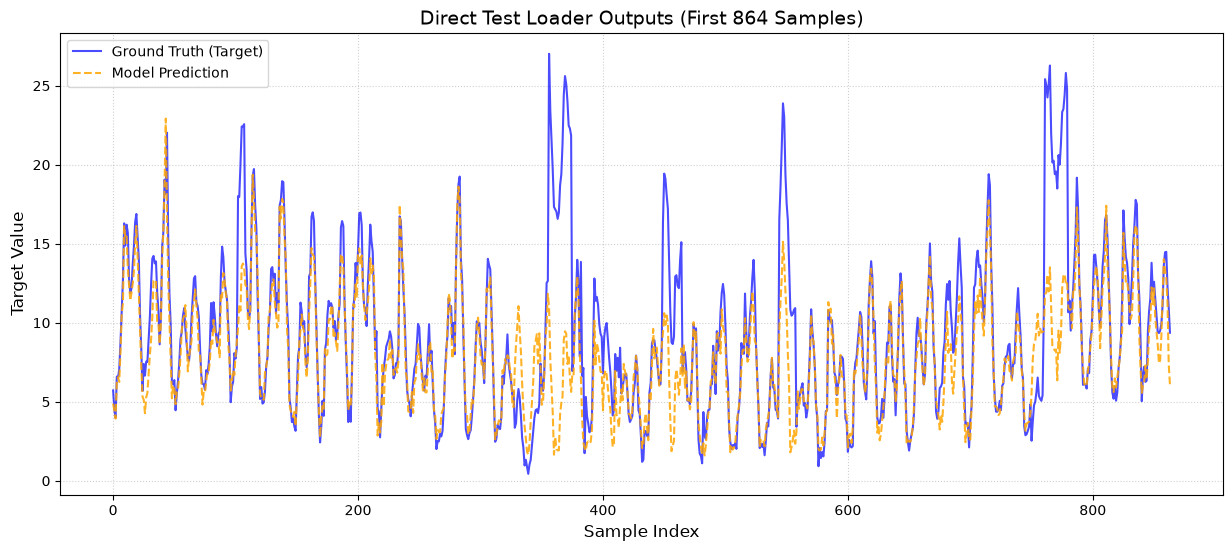

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# 1. Collect all predictions and ground truth directly from test_loader
all_preds = []
all_trues = []

best_model.eval()
with torch.no_grad():
    for test_inputs, test_targets in test_loader:
        test_inputs = test_inputs.to(device, dtype=torch.float32)

        preds = best_model(test_inputs).squeeze(-1)

        all_preds.extend(preds.cpu().numpy().flatten())
        all_trues.extend(test_targets.cpu().numpy().flatten())

all_preds = np.array(all_preds)
all_trues = np.array(all_trues)

# 2. Print exact stats
print("=== FROM TEST_LOADER DIRECTLY ===")
print(f"Target Range:     [{all_trues.min():.2f}, {all_trues.max():.2f}] | Mean: {all_trues.mean():.2f}")
print(f"Prediction Range: [{all_preds.min():.2f}, {all_preds.max():.2f}] | Mean: {all_preds.mean():.2f}")
print(f"Actual Computed MAE: {np.mean(np.abs(all_trues - all_preds)):.4f}")
print(f"Actual Computed MSE: {np.mean(np.square(all_trues - all_preds)):.4f}")
print(f"Actual Computed RMSE: {np.sqrt(np.mean(np.square(all_trues - all_preds))):.4f}")

# 3. Plot the first 864 steps directly from test_loader outputs
plt.figure(figsize=(15, 6))
plt.plot(all_trues[:864], label='Ground Truth (Target)', color='blue', alpha=0.7)
plt.plot(all_preds[:864], label='Model Prediction', color='orange', alpha=0.85, linestyle='--')
plt.title("Direct Test Loader Outputs (First 864 Samples)", fontsize=14)
plt.xlabel("Sample Index", fontsize=12)
plt.ylabel("Target Value", fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Testing Naive ensemble method

In [22]:
# 1. Load the best saved weights from a real PyTorch checkpoint
best_model = MyNN(
    input_dim=22,
    output_dim=1,
    num_hidden_layer=study.best_params['num_hidden_layer'],
    neurons_per_layer=study.best_params['neurons_per_layer'],
    dropout_rate=study.best_params['dropout_rate']).to(device)



averaged_state_dict = {}
state_dict_best = torch.load('../Artifacts/MyNN_Model/best_model.pth', map_location=device)
state_dict_best_final = torch.load('../Artifacts/MyNN_Model/model_at_99.pth', map_location=device)


for key in state_dict_best.keys():
    if state_dict_best[key].is_floating_point():
        averaged_state_dict[key] = (
            state_dict_best[key] + 
            state_dict_best_final[key] 
        ) / 2.0
    else:
        averaged_state_dict[key] = state_dict_best[key]  # Keep non-floating point tensors unchanged

best_model.load_state_dict(averaged_state_dict)


# # 2. Set model to evaluation mode
best_model.eval()


test_running_loss = 0.0
test_total_samples = 0


loss_fn = SmoothL1Loss(beta=1.0)

# 3. Disable gradient tracking
with torch.no_grad():
    for test_inputs, test_targets in test_loader:
        test_inputs = test_inputs.to(device, dtype=torch.float32)
        test_targets = test_targets.to(device, dtype=torch.float32)

        # Forward pass
        test_outputs = best_model(test_inputs)
     
        # Match dimensions exactly [Batch, SEQ_LEN]
        test_outputs = test_outputs.squeeze(dim=-1)
  

        # Calculate evaluation loss
        loss = loss_fn(test_outputs, test_targets)
   

        # Accumulate metrics
        test_running_loss += loss.item() * test_inputs.size(0)
        test_total_samples += test_targets.size(0)

# 4. Final test score
final_test_loss = test_running_loss / test_total_samples
print(f"\nEvaluation Completed!")
print(f"Test Set L1 Loss (MAE): {final_test_loss:.4f}")



Evaluation Completed!
Test Set L1 Loss (MAE): 1.4316


In [24]:
import pandas as pd
import numpy as np
from baselines import make_all_baselines

# 1. Load your data
train_df = pd.read_csv('../Artifacts/train_df.csv')
test_df = pd.read_csv('../Artifacts/test_df.csv')

# 2. Extract the forecast index (just the IDs and timestamps)
forecast_index = test_df[['series_id', 'timestamp']].copy()

# 3. Generate all baseline predictions
baseline_preds = make_all_baselines(train_df, forecast_index)

# 4. Print the MAE for each baseline to compare against your MyNN model
print("--- Baseline Benchmark Scores ---")
for model_name, pred_df in baseline_preds.items():
    mae = np.mean(np.abs(test_df['target'].values - pred_df['prediction'].values))
    rmse = np.mean(np.square(test_df['target'].values - pred_df['prediction'].values))
    print(f"{model_name:<20} MAE: {mae:.4f} | RMSE: {rmse:.4f}")

ModuleNotFoundError: No module named 'baselines'